# Pesquisa Operacional e Cálculo Aplicado — Deliverable 2

**DAMA Intelligence** · Alocação ótima de licenças de IA entre colaboradores e departamentos

No Deliverable 1 o problema foi formulado com duas variáveis e valores hipotéticos ("supondo que o Copiloto gera 50 pontos...").
Neste notebook o mesmo problema é resolvido com os dados da base do projeto:

1. o modelo do D1 é resolvido computacionalmente, como ponto de partida;
2. os parâmetros (custo por licença, orçamento, uso real, capacitação, ferramentas aprovadas) são extraídos dos CSVs;
3. um modelo de programação linear inteira decide **quem recebe qual licença**;
4. dez cenários são simulados (regras de orçamento, preços, cortes, capacitação);
5. a curva valor × orçamento é analisada com derivada, preço-sombra e elasticidade;
6. o modelo é aplicado às 18 empresas da base.

Para rodar: `pip install pandas matplotlib scipy pulp==2.9.0` e executar as células em ordem. O solver CBC já vem com o PuLP.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp
from scipy.optimize import curve_fit

warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

DADOS = Path('../../Deliverable1/machine-learning-ia/Data/csv')   # base sintética do projeto
SAIDA = Path('resultados'); SAIDA.mkdir(exist_ok=True)

EMPRESA = 'C01'                                   # NexoCode Soluções (grande, software, 11 departamentos)
MESES = [f'2026-{m:02d}' for m in range(1, 8)]    # jan a jul/2026, os 7 meses mais recentes da base
CAMBIO = 5.50                                     # premissa: R$ por US$ para o consumo pago em dólar
CURSOS_OBRIGATORIOS = ['Seguranca e Compliance', 'Governanca']
SOLVER = pulp.PULP_CBC_CMD(msg=0)
BONUS_MANTER = 0.01                               # desempate (em UE) a favor de manter a licença que a pessoa já tem

# paleta (texto em tinta neutra; cores só nas marcas)
AZUL, LARANJA, VERDE = '#2a78d6', '#eb6834', '#1baf7a'
TINTA, TINTA2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE,
    'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2, 'text.color': TINTA,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 150,
    'savefig.bbox': 'tight', 'axes.axisbelow': True,
})
brl = lambda x: f'R$ {x:,.0f}'.replace(',', '.')
print('PuLP', pulp.__version__)

PuLP 2.9.0


## 1. Ponto de partida: o modelo do Deliverable 1

$$\max Z = 50x_1 + 30x_2 \quad \text{s.a.} \quad 20x_1 + 10x_2 \le 1000,\quad x_1 + x_2 \le 40,\quad x_1, x_2 \ge 0$$

$x_1$ = licenças de Copiloto de Desenvolvimento, $x_2$ = licenças de Assistente Generativo.

In [2]:
d1 = pulp.LpProblem('Deliverable1', pulp.LpMaximize)
x1 = pulp.LpVariable('x1_copiloto', lowBound=0)
x2 = pulp.LpVariable('x2_assistente', lowBound=0)
d1 += 50 * x1 + 30 * x2
d1 += (20 * x1 + 10 * x2 <= 1000), 'orcamento'
d1 += (x1 + x2 <= 40), 'capacitados'
d1.solve(SOLVER)

print('status:', pulp.LpStatus[d1.status])
print(f'x1 = {x1.value():.0f}   x2 = {x2.value():.0f}   Z = {pulp.value(d1.objective):.0f}')
for nome, c in d1.constraints.items():
    print(f'{nome:12s} folga = {c.slack:6.1f}   preço-sombra = {c.pi:5.1f}')

status: Optimal
x1 = 40   x2 = 0   Z = 2000
orcamento    folga =  200.0   preço-sombra =  -0.0
capacitados  folga =   -0.0   preço-sombra =  50.0


**Leitura.** O ótimo do D1 é dar todas as 40 licenças ao Copiloto ($Z = 2.000$). Sobram R$ 200 de orçamento (preço-sombra zero), e o limite real é o número de pessoas capacitadas: cada capacitado a mais vale 50 pontos.

O modelo tem três limitações, e o D2 corrige as três:

- os coeficientes 50, 30, 20 e 10 eram suposições, e agora vêm dos dados;
- o modelo decidia quantidades agregadas, e agora decide quem recebe cada licença;
- havia uma única restrição de orçamento, e agora entram também as regras de governança, as categorias e a cobertura.

## 2. Dados e parâmetros

| Parâmetro | Origem | Como é calculado |
|---|---|---|
| $c_t$ custo mensal da licença | `ai_billing.csv` | custo em R$ ÷ licenças faturadas, jan–jul/2026, por empresa e ferramenta |
| $B_d$ orçamento do centro de custo | `ai_budgets.csv` | média mensal de 2026, descontado o consumo em US$ (`ai_billing`, convertido a R$ 5,50) |
| $v_{e,t}$ valor da licença | `ai_usage_logs.csv` | requisições bem-sucedidas por mês do colaborador na ferramenta ÷ mediana dos usuários da ferramenta na empresa |
| $a_{d,t}$ ferramenta aprovada | `approved_ai_tools.csv` | status "Aprovado" e departamento na lista de autorizados |
| $k_e$ capacitado | `training_records.csv` | concluiu curso de Segurança e Compliance ou de Governança |
| alocação atual | `ai_licenses.csv` | licenças com status "Ativa" |

**Unidade de valor.** $v_{e,t}$ é medido em **usuários-equivalentes (UE)**: 1 UE é o uso mensal de um usuário mediano daquela ferramenta. Normalizar pela mediana torna comparáveis ferramentas de natureza diferente. Um copiloto de código registra centenas de requisições por mês; um assistente de texto, algumas dezenas. Quem nunca usou a ferramenta tem $v = 0$.

In [3]:
ler = lambda nome, **kw: pd.read_csv(DADOS / f'{nome}.csv', **kw)
empresas = ler('companies'); departamentos = ler('departments'); colaboradores = ler('employees')
ferramentas = ler('ai_tools'); orcamentos = ler('ai_budgets'); faturas = ler('ai_billing')
licencas = ler('ai_licenses'); aprovacoes = ler('approved_ai_tools'); treinamentos = ler('training_records')
uso = ler('ai_usage_logs', usecols=['timestamp', 'employee_id', 'company_id', 'ai_tool_id',
                                    'request_count', 'request_status'])
uso = uso[(uso.request_status == 'success') & (uso.timestamp.str[:7].isin(MESES))]

CATEGORIA = dict(zip(ferramentas.ai_tool_id, ferramentas.tool_category))
NOME_FERR = dict(zip(ferramentas.ai_tool_id, ferramentas.tool_name))
NOME_DEP = dict(zip(departamentos.department_id, departamentos.department_name))
POR_ASSENTO = set(ferramentas[ferramentas.licensing_type.str.startswith('Por usu')].ai_tool_id)
print({n: len(df) for n, df in [('colaboradores', colaboradores), ('licencas', licencas),
                                 ('faturas', faturas), ('uso (sucesso, 2026)', uso)]})

{'colaboradores': 2356, 'licencas': 5605, 'faturas': 7025, 'uso (sucesso, 2026)': 168915}


In [4]:
def parametros(empresa):
    '''Extrai da base todos os parâmetros do modelo para uma empresa.'''
    deps = departamentos[departamentos.company_id == empresa]
    id_por_nome = dict(zip(deps.department_name, deps.department_id))
    ativos = colaboradores[(colaboradores.company_id == empresa) & (colaboradores.active)]
    dep_de = dict(zip(ativos.employee_id, ativos.department_id))

    fat = faturas[(faturas.company_id == empresa) & (faturas.billing_month.isin(MESES))]
    assento = fat[fat.currency == 'BRL']
    custo = (assento.groupby('ai_tool_id').total_cost.sum() / assento.groupby('ai_tool_id').usage_quantity.sum())

    # ferramentas por assento aprovadas, com preço conhecido (descarta descontinuadas sem fatura)
    aprov = {}
    for _, a in aprovacoes[(aprovacoes.company_id == empresa) & (aprovacoes.approval_status == 'Aprovado')].iterrows():
        if a.ai_tool_id not in POR_ASSENTO or a.ai_tool_id not in custo.index:
            continue
        txt = str(a.allowed_departments)
        aprov[a.ai_tool_id] = set(id_por_nome.values()) if txt.startswith('Todos') else {
            id_por_nome[n.strip()] for n in re.split('[;,]', txt) if n.strip() in id_por_nome}
    T = sorted(aprov)

    orc = (orcamentos[(orcamentos.company_id == empresa) & (orcamentos.year == 2026) & (orcamentos.month <= 7)]
           .groupby('cost_center').budget_amount.mean())
    consumo_usd = fat[fat.currency == 'USD'].groupby('cost_center').total_cost.sum() / len(MESES)
    B = (orc - consumo_usd.reindex(orc.index).fillna(0) * CAMBIO)
    B.index = [cc.replace('CC-', '') for cc in B.index]
    B = B.reindex(sorted(set(dep_de.values()))).fillna(0)

    u = uso[(uso.company_id == empresa) & (uso.ai_tool_id.isin(T)) & (uso.employee_id.isin(dep_de))]
    mensal = u.groupby(['employee_id', 'ai_tool_id']).request_count.sum() / len(MESES)
    mediana = mensal.groupby('ai_tool_id').median()
    v = (mensal / mediana.reindex(mensal.index.get_level_values('ai_tool_id')).values).to_dict()

    feitos = treinamentos[(treinamentos.company_id == empresa) & (treinamentos.completion_status == 'Concluido')
                          & (treinamentos.course_category.isin(CURSOS_OBRIGATORIOS))]
    k = set(feitos.employee_id) & set(dep_de)

    pares = [(e, t) for e in dep_de for t in T if dep_de[e] in aprov[t]]
    lic = licencas[(licencas.company_id == empresa) & (licencas.license_status == 'Ativa')
                   & (licencas.employee_id.isin(dep_de))]
    atuais = set(zip(lic.employee_id, lic.ai_tool_id)) & set(pares)
    return dict(empresa=empresa, dep_de=dep_de, T=T, aprov=aprov, c=custo.reindex(T).to_dict(), B=B,
                v=v, mediana=mediana, k=k, pares=pares, lic=lic, atuais=atuais)

P = parametros(EMPRESA)
print(f"{empresas.set_index('company_id').company_name[EMPRESA]}: {len(P['dep_de'])} colaboradores ativos, "
      f"{len(P['B'])} centros de custo, {len(P['k'])} capacitados, {len(P['pares'])} pares colaborador×ferramenta elegíveis")
pd.DataFrame({
    'ferramenta': [NOME_FERR[t] for t in P['T']],
    'categoria': [CATEGORIA[t] for t in P['T']],
    'custo mensal (R$)': [round(P['c'][t], 2) for t in P['T']],
    'departamentos autorizados': [len(P['aprov'][t]) for t in P['T']],
    'mediana req./mês (1 UE)': [round(P['mediana'].get(t, np.nan)) for t in P['T']],
}, index=P['T'])

NexoCode Solucoes: 336 colaboradores ativos, 11 centros de custo, 67 capacitados, 1554 pares colaborador×ferramenta elegíveis


,ferramenta,categoria,custo mensal (R$),departamentos autorizados,mediana req./mês (1 UE)
T02,Claude for Work,Assistente Generativo,159.81,11,71
T05,GitHub Copilot,Copiloto de Desenvolvimento,133.14,5,236
T07,Tabnine,Copiloto de Desenvolvimento,213.57,11,217
T08,Microsoft 365 Copilot,IA Integrada a Produtividade,192.02,11,55
T09,Notion AI,IA Integrada a Produtividade,179.64,11,53


## 3. Diagnóstico da alocação atual

Antes de otimizar, vale olhar como as licenças estão distribuídas hoje.

In [5]:
def avaliar_atual(P):
    lic = P['lic']
    fora = lic[~lic.apply(lambda r: r.ai_tool_id in P['aprov'] and P['dep_de'][r.employee_id] in P['aprov'][r.ai_tool_id], axis=1)]
    dentro = lic.drop(fora.index)[['employee_id', 'ai_tool_id']].drop_duplicates()
    dentro = dentro.assign(department_id=dentro.employee_id.map(P['dep_de']),
                           v=[P['v'].get((e, t), 0.0) for e, t in zip(dentro.employee_id, dentro.ai_tool_id)],
                           c=dentro.ai_tool_id.map(P['c']), categoria=dentro.ai_tool_id.map(CATEGORIA))
    redundantes = int((dentro.groupby(['employee_id', 'categoria']).size() - 1).clip(lower=0).sum())
    sem_licenca = len(set(P['dep_de']) - set(dentro.employee_id))
    # valor efetivo: duas ferramentas da mesma categoria são substitutas, conta só a de maior uso
    efetivo = dentro.groupby(['employee_id', 'categoria']).v.max().sum()
    return dict(df=dentro, n=len(dentro), custo=dentro.c.sum(), valor=efetivo, valor_bruto=dentro.v.sum(),
                ociosas=int((dentro.v == 0).sum()), redundantes=redundantes, fora_politica=len(fora),
                sem_licenca=sem_licenca)

A0 = avaliar_atual(P)
print(f"Licenças ativas (ferramentas aprovadas): {A0['n']}  |  custo mensal {brl(A0['custo'])}  |  valor efetivo {A0['valor']:.1f} UE "
      f"(bruto {A0['valor_bruto']:.1f} UE, contando em dobro quem tem duas ferramentas da mesma categoria)")
print(f"  ociosas (sem nenhum uso em 2026):       {A0['ociosas']} ({A0['ociosas']/A0['n']:.0%})")
print(f"  redundantes (2 ferramentas da mesma categoria para a mesma pessoa): {A0['redundantes']}")
print(f"  licenças ativas de ferramentas fora da política: {A0['fora_politica']}")
print(f"  colaboradores ativos sem nenhuma licença: {A0['sem_licenca']} de {len(P['dep_de'])}")
print(f"Orçamento mensal disponível (soma dos centros de custo): {brl(P['B'].sum())}")

Licenças ativas (ferramentas aprovadas): 468  |  custo mensal R$ 84.626  |  valor efetivo 522.2 UE (bruto 572.7 UE, contando em dobro quem tem duas ferramentas da mesma categoria)
  ociosas (sem nenhum uso em 2026):       96 (21%)
  redundantes (2 ferramentas da mesma categoria para a mesma pessoa): 42
  licenças ativas de ferramentas fora da política: 36
  colaboradores ativos sem nenhuma licença: 56 de 336
Orçamento mensal disponível (soma dos centros de custo): R$ 94.369


,orcado,gasto_atual,uso_do_orcamento
Engenharia de Software (D01),6598.54,23323.80,3.53
Vendas (D06),6298.17,12057.91,1.91
Marketing (D07),2094.87,3637.51,1.74
Suporte ao Cliente (D08),8029.27,11148.10,1.39
Qualidade (QA) (D04),12039.28,11258.83,0.94
Dados e Analytics (D05),7969.57,5491.00,0.69
DevOps e Infraestrutura (D02),11210.53,7230.48,0.64
Financeiro (D10),5540.18,3461.10,0.62
Produto (D03),11507.75,4459.35,0.39
RH (D09),13599.81,2365.95,0.17


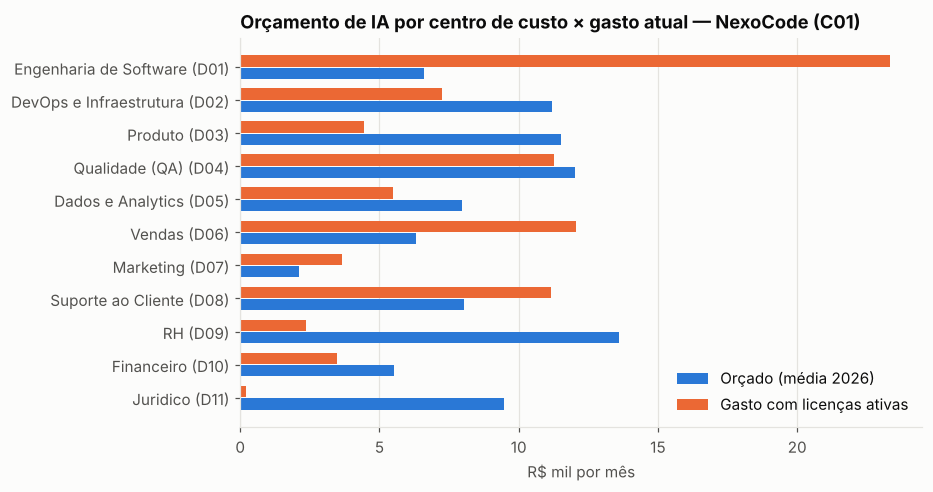

In [6]:
por_cc = pd.DataFrame({'orcado': P['B'], 'gasto_atual': A0['df'].groupby('department_id').c.sum()}).fillna(0)
por_cc['uso_do_orcamento'] = (por_cc.gasto_atual / por_cc.orcado)
por_cc.index = [f"{NOME_DEP[d]} ({d[-3:]})" for d in por_cc.index]
display(por_cc.round(2).sort_values('uso_do_orcamento', ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(por_cc)); h = 0.38
ax.barh(y + h/2, por_cc.orcado / 1000, h - 0.04, color=AZUL, label='Orçado (média 2026)')
ax.barh(y - h/2, por_cc.gasto_atual / 1000, h - 0.04, color=LARANJA, label='Gasto com licenças ativas')
ax.set_yticks(y, por_cc.index); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_xlabel('R$ mil por mês')
ax.set_title('Orçamento de IA por centro de custo × gasto atual — NexoCode (C01)')
ax.legend(loc='lower right')
fig.savefig(SAIDA / 'fig1_orcado_vs_gasto.png'); plt.show()

**Leitura.** No total, o gasto atual cabe no orçamento. A distribuição entre centros de custo, porém, não segue o orçado: Engenharia de Software gasta mais de três vezes o que tem, e RH, Jurídico e Produto usam uma fração do seu. Além disso, uma em cada cinco licenças ativas não teve nenhum uso em 2026. Os dois problemas são de alocação, não de volume de dinheiro, e por isso cabem em um modelo de otimização.

## 4. Modelo matemático

**Conjuntos.** $E$ colaboradores ativos; $T$ ferramentas por assento aprovadas; $D$ centros de custo; $G$ categorias de ferramenta; $P \subseteq E\times T$ pares elegíveis ($a_{d(e),t}=1$).

**Variáveis.** $y_{e,t} \in \{0,1\}$: o colaborador $e$ recebe licença da ferramenta $t$. No cenário de capacitação, $z_e \in \{0,1\}$: o colaborador $e$ é capacitado.

**Objetivo.** Maximizar o uso produtivo total, em usuários-equivalentes:

$$\max V = \sum_{(e,t)\in P} v_{e,t}\, y_{e,t}$$

**Restrições.**

| # | Restrição | Forma |
|---|---|---|
| R1 | Orçamento corporativo | $\sum_{(e,t)\in P} c_t\, y_{e,t} \le \sum_d B_d$ |
| R1' | Orçamento rígido por centro de custo (cenário) | $\sum_{(e,t)\in P:\, d(e)=d} c_t\, y_{e,t} \le B_d \quad \forall d$ |
| R2 | No máximo uma ferramenta por categoria por pessoa | $\sum_{t\in g} y_{e,t} \le 1 \quad \forall e, g$ |
| R3 | Governança: só ferramentas aprovadas para o departamento | $y_{e,t}$ existe apenas se $(e,t)\in P$ |
| R4 | Cobertura: todo colaborador ativo tem acesso básico | $\sum_t y_{e,t} \ge 1 \quad \forall e$ |
| R5 | Níveis de autonomia (cenário): sem capacitação, só a licença básica | $\sum_t y_{e,t} \le 1 + (n_e - 1)\, z_e \quad \forall e \notin K$ |
| R6 | Capacidade de capacitação (cenário) | $\sum_e z_e \le Q$ |

R4 e R5 trazem para o modelo a lógica do DAMA. Todos têm um nível básico de acesso à IA, e o acesso a mais ferramentas depende de letramento comprovado.

**Formulação dual (custo mínimo).** Minimizar $\sum c_t y_{e,t}$ sujeito a $V \ge V_0$, R2, R3 e R4. A pergunta é quanto custaria entregar o mesmo uso de hoje.

In [7]:
def resolver(P, orcamento='total', fator_orc=1.0, fator_preco=1.0, cobertura=True,
             niveis=False, cap_treino=0, meta_valor=None, relaxar=False, mesma_categoria=False,
             bonus_manter=BONUS_MANTER, max_revogacoes=None):
    '''Monta e resolve o modelo. Devolve status, valor, custo, licenças e a solução.'''
    pares, dep_de, T = P['pares'], P['dep_de'], P['T']
    tipo = 'Continuous' if relaxar else 'Binary'
    sentido = pulp.LpMinimize if meta_valor is not None else pulp.LpMaximize
    m = pulp.LpProblem('alocacao_licencas_IA', sentido)
    y = pulp.LpVariable.dicts('y', pares, lowBound=0, upBound=1, cat=tipo)
    c = {t: P['c'][t] * fator_preco for t in T}
    v = {q: P['v'].get(q, 0.0) for q in pares}
    valor = pulp.lpSum(v[q] * y[q] for q in pares)
    custo = pulp.lpSum(c[t] * y[(e, t)] for e, t in pares)

    atuais = P['atuais']
    if meta_valor is None:
        # desempate: entre opções de valor igual, prefere manter a licença que a pessoa já tem
        m += valor + bonus_manter * pulp.lpSum(y[q] for q in pares if q in atuais)
        if orcamento == 'cc':                                                       # R1'
            for d in P['B'].index:
                m += (pulp.lpSum(c[t] * y[(e, t)] for e, t in pares if dep_de[e] == d)
                      <= P['B'][d] * fator_orc), f'orc_{d}'
        else:                                                                       # R1
            m += (custo <= P['B'].sum() * fator_orc), 'orc_total'
    else:
        m += custo
        m += (valor >= meta_valor), 'meta_valor'
    if max_revogacoes is not None:                                                  # R7 (transição gradual)
        m += (pulp.lpSum(1 - y[q] for q in atuais) <= max_revogacoes), 'max_revogacoes'

    ferr_de = {e: [t for t in T if (e, t) in y] for e in dep_de}
    for e, ts in ferr_de.items():
        for g in {CATEGORIA[t] for t in ts}:                                        # R2
            mesma = [t for t in ts if CATEGORIA[t] == g]
            if len(mesma) > 1 and not mesma_categoria:
                m += (pulp.lpSum(y[(e, t)] for t in mesma) <= 1), f'cat_{e}_{g[:12]}'
        if cobertura and ts:                                                        # R4
            m += (pulp.lpSum(y[(e, t)] for t in ts) >= 1), f'cob_{e}'

    z = {}
    if niveis:                                                                      # R5 e R6
        sem_treino = [e for e in dep_de if e not in P['k'] and ferr_de[e]]
        if cap_treino:
            z = pulp.LpVariable.dicts('z', sem_treino, lowBound=0, upBound=1, cat=tipo)
            m += (pulp.lpSum(z.values()) <= cap_treino), 'cap_treino'
        for e in sem_treino:
            n_e = len(ferr_de[e])
            m += (pulp.lpSum(y[(e, t)] for t in ferr_de[e]) <= 1 + (n_e - 1) * (z[e] if z else 0)), f'nivel_{e}'

    m.solve(SOLVER)
    status = pulp.LpStatus[m.status]
    sol = pd.DataFrame([(e, t, dep_de[e], y[(e, t)].value() or 0.0, v[(e, t)], c[t]) for e, t in pares],
                       columns=['employee_id', 'ai_tool_id', 'department_id', 'y', 'v', 'c'])
    sol = sol[sol.y > 1e-6].reset_index(drop=True)
    treinar = [e for e, var in z.items() if (var.value() or 0) > 0.5]
    return dict(status=status, valor=float((sol.v * sol.y).sum()), custo=float((sol.c * sol.y).sum()),
                n=float(sol.y.sum()), sol=sol, modelo=m, treinar=treinar)

base = resolver(P)
print(base['status'], f"| {base['n']:.0f} licenças | {brl(base['custo'])} | {base['valor']:.1f} UE "
      f"| {len(base['modelo'].variables())} variáveis, {len(base['modelo'].constraints)} restrições")

Optimal | 576 licenças | R$ 94.364 | 1307.5 UE | 1554 variáveis, 883 restrições


## 5. Validação do modelo

Quatro verificações:

1. a solução respeita todas as restrições, conferidas fora do solver;
2. a relaxação linear (variáveis entre 0 e 1) dá um limite superior para o valor; a distância entre ela e a solução inteira mostra o quanto a solução está perto do ótimo;
3. o solver reproduz o resultado do D1 (feito na seção 1);
4. uma heurística gulosa (maior valor por real primeiro) serve de comparação: o ótimo não pode ficar abaixo dela.

In [8]:
def verificar(P, R, orcamento='total', cobertura=True):
    s = R['sol'][R['sol'].y > 0.5]
    assert R['custo'] <= P['B'].sum() + 1e-6, 'orçamento total violado'
    if orcamento == 'cc':
        assert (s.groupby('department_id').c.sum() <= P['B'] + 1e-6).reindex(s.department_id.unique()).all()
    assert (s.assign(g=s.ai_tool_id.map(CATEGORIA)).groupby(['employee_id', 'g']).size() <= 1).all(), 'R2 violada'
    assert all(P['dep_de'][e] in P['aprov'][t] for e, t in zip(s.employee_id, s.ai_tool_id)), 'R3 violada'
    if cobertura:
        assert set(s.employee_id) == {e for e in P['dep_de'] if any((e, t) in set(P['pares']) for t in P['T'])}, 'R4 violada'
    return True

print('restrições conferidas:', verificar(P, base))
relax = resolver(P, relaxar=True)
gap = (relax['valor'] - base['valor']) / relax['valor']
print(f"relaxação linear = {relax['valor']:.2f} UE | inteiro = {base['valor']:.2f} UE | gap = {gap:.4%}")

def guloso(P):
    '''Cobertura com a licença de maior v/c por pessoa; depois o restante por v/c decrescente.'''
    orc = P['B'].sum(); usado = set(); cats = set(); gasto = 0; valor = 0
    cand = sorted(P['pares'], key=lambda q: -(P['v'].get(q, 0) / P['c'][q[1]]))
    for e in P['dep_de']:
        q = next((q for q in cand if q[0] == e), None)
        if q: usado.add(q); cats.add((e, CATEGORIA[q[1]])); gasto += P['c'][q[1]]; valor += P['v'].get(q, 0)
    for q in cand:
        e, t = q
        if q in usado or (e, CATEGORIA[t]) in cats or P['v'].get(q, 0) <= 0 or gasto + P['c'][t] > orc:
            continue
        usado.add(q); cats.add((e, CATEGORIA[t])); gasto += P['c'][t]; valor += P['v'].get(q, 0)
    return valor, gasto

vg, cg = guloso(P)
print(f"heurística gulosa = {vg:.1f} UE ({brl(cg)}) | ótimo = {base['valor']:.1f} UE  -> ganho do modelo: {base['valor']/vg-1:+.1%}")

restrições conferidas: True
relaxação linear = 1307.49 UE | inteiro = 1307.46 UE | gap = 0.0022%
heurística gulosa = 1272.0 UE (R$ 94.286) | ótimo = 1307.5 UE  -> ganho do modelo: +2.8%


## 6. Simulação de cenários

| Cenário | O que muda |
|---|---|
| A0 Atual | Licenças ativas hoje (não é otimização) |
| A1 Base | Orçamento corporativo, uma ferramenta por categoria, só aprovadas, cobertura para todos |
| A2 Orçamento por centro de custo | Cada departamento limitado ao próprio orçado (R1') |
| A3 Sem cobertura | Retira R4: mostra quanto custa garantir acesso a todos |
| A4 Níveis de autonomia | Sem capacitação, só a licença básica (R5, com $Q=0$) |
| A5 Níveis + 40 capacitações | Permite capacitar até 40 pessoas escolhidas pelo modelo (R6) |
| A6 Custo mínimo | Formulação dual: entregar o valor de hoje ao menor custo |
| A7 Reajuste de 20% | Preço de todas as licenças +20% |
| A8 Corte de 20% | Orçamento −20% |
| A9 Orçamento +20% | Orçamento +20% |
| A10 Transição gradual | No máximo 100 licenças atuais revogadas no mês (R7) |
| A11 Sem limite por categoria | Retira R2: duas ferramentas da mesma categoria somam valor |

In [9]:
def linha(nome, R, obs=''):
    return dict(cenario=nome, status=R.get('status', '—'), licencas=round(R['n']), custo=round(R['custo']),
                valor_UE=round(R['valor'], 1), UE_por_mil_reais=round(R['valor'] / R['custo'] * 1000, 2) if R['custo'] else np.nan,
                obs=obs)

cen = []
cen.append(linha('A0 Atual', dict(A0, status='—'), f"{A0['ociosas']} ociosas, {A0['redundantes']} redundantes"))
cen.append(linha('A1 Base', base))
a2 = resolver(P, orcamento='cc')
if a2['status'] != 'Optimal':
    custo_cob = {d: min(P['c'][t] for t in P['T'] if d in P['aprov'][t]) * sum(1 for e in P['dep_de'] if P['dep_de'][e] == d) for d in P['B'].index}
    falta = [f"{NOME_DEP[d]}" for d in P['B'].index if custo_cob[d] > P['B'][d] + 1e-6]
    a2 = resolver(P, orcamento='cc', cobertura=False)
    cen.append(linha('A2 Orçamento por CC', a2, 'inviável com cobertura (' + ', '.join(falta) + '); resolvido sem R4'))
else:
    cen.append(linha('A2 Orçamento por CC', a2))
a3 = resolver(P, cobertura=False); cen.append(linha('A3 Sem cobertura', a3))
a4 = resolver(P, niveis=True); cen.append(linha('A4 Níveis de autonomia', a4, f"{len(P['k'])} capacitados hoje"))
a5 = resolver(P, niveis=True, cap_treino=40); cen.append(linha('A5 Níveis + 40 capacitações', a5))
a6 = resolver(P, meta_valor=A0['valor']); cen.append(linha('A6 Custo mínimo (valor de hoje)', a6, f"meta: {A0['valor']:.1f} UE"))
a7 = resolver(P, fator_preco=1.2); cen.append(linha('A7 Reajuste de 20%', a7))
a8 = resolver(P, fator_orc=0.8); cen.append(linha('A8 Corte de 20%', a8))
a9 = resolver(P, fator_orc=1.2); cen.append(linha('A9 Orçamento +20%', a9))
a10 = resolver(P, max_revogacoes=100); cen.append(linha('A10 Transição: até 100 revogações', a10))
a11 = resolver(P, mesma_categoria=True); cen.append(linha('A11 Sem limite por categoria', a11, 'premissa de substituição relaxada'))
cenarios = pd.DataFrame(cen)
cenarios['vs_atual'] = (cenarios.valor_UE / A0['valor'] - 1).map('{:+.0%}'.format)
cenarios.to_csv(SAIDA / f'cenarios_{EMPRESA}.csv', index=False)
cenarios

,cenario,status,licencas,custo,valor_UE,UE_por_mil_reais,obs,vs_atual
0,A0 Atual,—,468,84626,522.2,6.17,"96 ociosas, 42 redundantes",+0%
1,A1 Base,Optimal,576,94364,1307.5,13.86,,+150%
2,A2 Orçamento por CC,Optimal,429,73075,1052.6,14.41,inviável com cobertura (Engenharia de Software...,+102%
3,A3 Sem cobertura,Optimal,554,94368,1347.9,14.28,,+158%
4,A4 Níveis de autonomia,Optimal,443,79692,915.3,11.49,67 capacitados hoje,+75%
5,A5 Níveis + 40 capacitações,Optimal,524,94234,1106.7,11.74,,+112%
6,A6 Custo mínimo (valor de hoje),Optimal,336,48096,723.4,15.04,meta: 522.2 UE,+39%
7,A7 Reajuste de 20%,Optimal,496,94365,1190.5,12.62,,+128%
8,A8 Corte de 20%,Optimal,480,75491,1159.4,15.36,,+122%
9,A9 Orçamento +20%,Optimal,668,113238,1367.5,12.08,,+162%


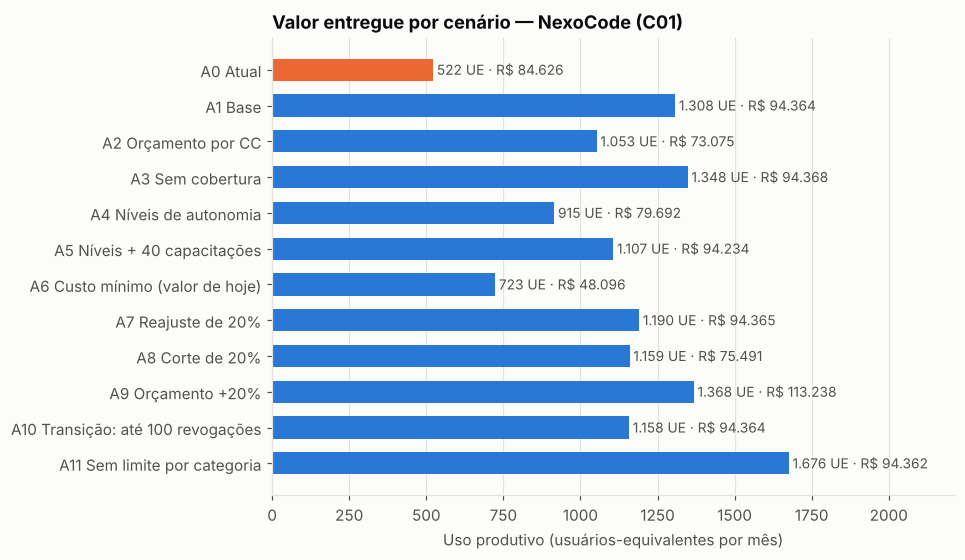

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.4))
cs = cenarios.iloc[::-1]
cores = [LARANJA if n.startswith('A0') else AZUL for n in cs.cenario]
ax.barh(cs.cenario, cs.valor_UE, color=cores, height=0.62)
for yv, (vl, ct) in enumerate(zip(cs.valor_UE, cs.custo)):
    ax.text(vl + 12, yv, f"{vl:,.0f} UE · {brl(ct)}".replace(',', '.'), va='center', color=TINTA2, fontsize=9)
ax.set_xlim(0, cs.valor_UE.max() * 1.32); ax.grid(axis='y', visible=False)
ax.set_xlabel('Uso produtivo (usuários-equivalentes por mês)')
ax.set_title('Valor entregue por cenário — NexoCode (C01)')
fig.savefig(SAIDA / 'fig2_cenarios.png'); plt.show()

## 7. Plano de ação de licenças (cenário base)

Comparando a solução ótima com as licenças ativas, cada licença vira uma de três ações: manter, revogar ou atribuir.

In [11]:
otima = base['sol'][base['sol'].y > 0.5][['employee_id', 'ai_tool_id', 'department_id', 'v', 'c']]
atual = A0['df'][['employee_id', 'ai_tool_id', 'department_id', 'v', 'c']]
plano = otima.merge(atual, how='outer', on=['employee_id', 'ai_tool_id', 'department_id', 'v', 'c'], indicator=True)
plano['acao'] = plano._merge.map({'both': 'manter', 'left_only': 'atribuir', 'right_only': 'revogar'})
plano = plano.drop(columns='_merge').assign(ferramenta=lambda d: d.ai_tool_id.map(NOME_FERR),
                                           departamento=lambda d: d.department_id.map(NOME_DEP))
plano.sort_values(['acao', 'department_id', 'employee_id']).to_csv(SAIDA / f'plano_licencas_{EMPRESA}.csv', index=False)

resumo = plano.pivot_table(index='departamento', columns='acao', values='employee_id', aggfunc='count', fill_value=0)
resumo['licenças hoje'] = resumo.get('manter', 0) + resumo.get('revogar', 0)
resumo['licenças no ótimo'] = resumo.get('manter', 0) + resumo.get('atribuir', 0)
print(plano.groupby('acao').agg(licencas=('c', 'size'), custo_mensal=('c', 'sum'), valor_UE=('v', 'sum')).round(1))
resumo.loc['Total'] = resumo.sum()
resumo

          licencas  custo_mensal  valor_UE
acao                                      
atribuir       415       67564.6     956.8
revogar        307       57826.9     222.1
manter         161       26799.2     350.6


acao,atribuir,revogar,manter,licenças hoje,licenças no ótimo
departamento,,,,,
Dados e Analytics,23,22,9,31,32
DevOps e Infraestrutura,45,32,8,40,53
Engenharia de Software,162,82,50,132,212
Financeiro,13,14,5,19,18
Juridico,1,1,0,1,1
Marketing,11,13,7,20,18
Produto,26,13,11,24,37
Qualidade (QA),50,46,17,63,67
RH,11,8,5,13,16


In [12]:
# o mínimo de revogações é o número de licenças redundantes: R2 obriga a tirar uma de cada par
minimo = A0['redundantes']
trans = []
for r_max in [minimo, 50, 100, 150, 200, 300, len(P['atuais'])]:
    R = resolver(P, max_revogacoes=r_max)
    assert R['status'] == 'Optimal', (r_max, R['status'])
    s = R['sol'][R['sol'].y > 0.5]
    trans.append(dict(revogacoes_permitidas=r_max, revogadas=len(P['atuais'] - set(zip(s.employee_id, s.ai_tool_id))),
                      licencas=len(s), custo=round(R['custo']), valor_UE=round(R['valor'], 1),
                      pct_do_ganho=(R['valor'] - A0['valor']) / (base['valor'] - A0['valor'])))
trans = pd.DataFrame(trans)
trans.to_csv(SAIDA / f'transicao_{EMPRESA}.csv', index=False)
print(f'Transição gradual: quanto do ganho do cenário base se obtém com um limite de revogações (mínimo = {minimo}, só as redundantes)')
trans.assign(pct_do_ganho=trans.pct_do_ganho.map('{:.0%}'.format))

Transição gradual: quanto do ganho do cenário base se obtém com um limite de revogações (mínimo = 42, só as redundantes)


,revogacoes_permitidas,revogadas,licencas,custo,valor_UE,pct_do_ganho
0,42,42,550,94357,980.9,58%
1,50,50,552,94364,1015.9,63%
2,100,100,557,94364,1157.7,81%
3,150,150,558,94366,1235.6,91%
4,200,200,564,94368,1275.9,96%
5,300,300,577,94366,1307.1,100%
6,468,307,576,94364,1307.5,100%


In [13]:
print('Licenças por ferramenta: hoje × ótimo')
pd.DataFrame({'hoje': atual.ai_tool_id.map(NOME_FERR).value_counts(),
              'ótimo': otima.ai_tool_id.map(NOME_FERR).value_counts()}).fillna(0).astype(int)

Licenças por ferramenta: hoje × ótimo


,hoje,ótimo
ai_tool_id,,
Claude for Work,131,215
GitHub Copilot,28,157
Microsoft 365 Copilot,146,53
Notion AI,85,98
Tabnine,78,53


## 8. Cálculo aplicado: valor marginal do orçamento

A pergunta é quanto rende cada real a mais (ou a menos) de orçamento. O modelo é resolvido para orçamentos de 50% a 160% do atual. A curva $V(B)$ resultante é então analisada de três formas:

- **preço-sombra** $\lambda = \partial V / \partial B$, lido do dual da restrição R1 na relaxação linear (exato localmente);
- **derivada numérica** por diferenças centrais na curva;
- **ajuste contínuo** $V(B) = a - b\,e^{-B/\beta}$, cuja derivada $V'(B) = \tfrac{b}{\beta}\,e^{-B/\beta}$ é decrescente, ou seja, rendimentos marginais decrescentes.

A elasticidade $\varepsilon = V'(B)\cdot B/V$ diz quanto o valor cresce, em %, para cada 1% de orçamento.

In [14]:
B0 = P['B'].sum()
fatores = np.round(np.arange(0.50, 1.601, 0.05), 2)
pontos = []
for f in fatores:
    R = resolver(P, fator_orc=f)
    L = resolver(P, fator_orc=f, relaxar=True)
    ok = R['status'] == 'Optimal'
    pontos.append(dict(fator=f, orcamento=B0 * f, status=R['status'],
                       valor=R['valor'] if ok else np.nan, custo=R['custo'] if ok else np.nan,
                       preco_sombra=L['modelo'].constraints['orc_total'].pi if L['status'] == 'Optimal' else np.nan))
curva = pd.DataFrame(pontos)
V_inf = resolver(P, fator_orc=50)['valor']        # orçamento ilimitado: teto de valor
B_min = resolver(P, meta_valor=0)['custo']        # menor orçamento viável: o custo de cobrir todo mundo
R_min = resolver(P, fator_orc=B_min / B0 + 1e-9)
curva = pd.concat([curva, pd.DataFrame([dict(fator=B_min / B0, orcamento=B_min, status=R_min['status'],
                                             valor=R_min['valor'], custo=R_min['custo'], preco_sombra=np.nan)])])
curva = curva.sort_values('orcamento').reset_index(drop=True)
curva['derivada_numerica'] = np.nan
ok = curva.valor.notna()
curva.loc[ok, 'derivada_numerica'] = np.gradient(curva.loc[ok, 'valor'], curva.loc[ok, 'orcamento'])
viavel = curva[ok]

f = lambda B, a, b, beta: a - b * np.exp(-B / beta)
(a, b, beta), _ = curve_fit(f, viavel.orcamento, viavel.valor, p0=[V_inf, V_inf, B0], maxfev=20000)
df_dB = lambda B: b / beta * np.exp(-B / beta)
r2 = 1 - ((viavel.valor - f(viavel.orcamento, a, b, beta))**2).sum() / ((viavel.valor - viavel.valor.mean())**2).sum()

V0 = base['valor']
lam = curva.loc[np.isclose(curva.fator, 1.0), 'preco_sombra'].item()
num = curva.loc[np.isclose(curva.fator, 1.0), 'derivada_numerica'].item()
print(f"teto de valor (orçamento ilimitado) V∞ = {V_inf:.1f} UE; menor orçamento viável = {brl(B_min)} (custo de cobrir todo mundo)")
print(f"ajuste: a = {a:.1f}, b = {b:.1f}, β = {beta:,.0f}   R² = {r2:.4f}")
print(f"no orçamento atual ({brl(B0)}):")
print(f"  preço-sombra (dual LP)  λ = {lam*1000:.2f} UE por R$ 1.000")
print(f"  derivada numérica          {num*1000:.2f} UE por R$ 1.000")
print(f"  derivada do ajuste         {df_dB(B0)*1000:.2f} UE por R$ 1.000")
print(f"  elasticidade ε = {lam * B0 / V0:.2f}  -> +1% de orçamento rende +{lam * B0 / V0:.2f}% de valor")
B95 = -beta * np.log((a - 0.95 * V_inf) / b) if a > 0.95 * V_inf else np.nan
print(f"orçamento para chegar a 95% do teto: {brl(B95)} ({B95 / B0:.0%} do atual)" if not np.isnan(B95) else 'teto de 95% fora do alcance do ajuste')
curva.to_csv(SAIDA / f'curva_orcamento_{EMPRESA}.csv', index=False)

teto de valor (orçamento ilimitado) V∞ = 1401.5 UE; menor orçamento viável = R$ 48.096 (custo de cobrir todo mundo)
ajuste: a = 1427.7, b = 4014.8, β = 27,490   R² = 0.9985
no orçamento atual (R$ 94.369):
  preço-sombra (dual LP)  λ = 5.49 UE por R$ 1.000
  derivada numérica          5.36 UE por R$ 1.000
  derivada do ajuste         4.72 UE por R$ 1.000
  elasticidade ε = 0.40  -> +1% de orçamento rende +0.40% de valor
orçamento para chegar a 95% do teto: R$ 102.548 (109% do atual)


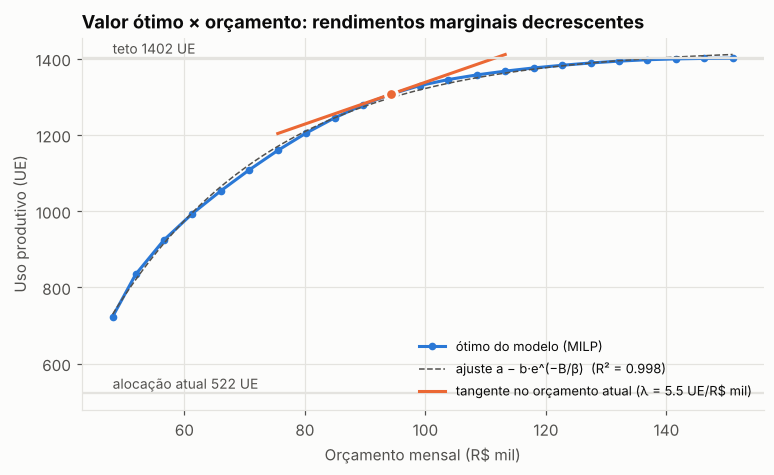

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(viavel.orcamento / 1000, viavel.valor, color=AZUL, lw=2, marker='o', ms=4, label='ótimo do modelo (MILP)')
grade = np.linspace(viavel.orcamento.min(), viavel.orcamento.max(), 200)
ax.plot(grade / 1000, f(grade, a, b, beta), color=TINTA2, lw=1, ls='--', label=f'ajuste a − b·e^(−B/β)  (R² = {r2:.3f})')
tg = np.linspace(B0 * 0.8, B0 * 1.2, 2)
ax.plot(tg / 1000, V0 + lam * (tg - B0), color=LARANJA, lw=2, label=f'tangente no orçamento atual (λ = {lam*1000:.1f} UE/R$ mil)')
ax.scatter([B0 / 1000], [V0], s=60, color=LARANJA, zorder=5, edgecolor=FUNDO, linewidth=2)
ax.axhline(V_inf, color=GRADE, lw=1.5); ax.text(viavel.orcamento.min() / 1000, V_inf + 12, f'teto {V_inf:.0f} UE', color=TINTA2, fontsize=9)
ax.axhline(A0['valor'], color=GRADE, lw=1.5); ax.text(viavel.orcamento.min() / 1000, A0['valor'] + 12, f"alocação atual {A0['valor']:.0f} UE", color=TINTA2, fontsize=9)
ax.set_xlabel('Orçamento mensal (R$ mil)'); ax.set_ylabel('Uso produtivo (UE)')
ax.set_title('Valor ótimo × orçamento: rendimentos marginais decrescentes')
ax.legend(loc='lower right', fontsize=8.5)
fig.savefig(SAIDA / 'fig3_curva_orcamento.png'); plt.show()

## 9. Capacitação como investimento

No cenário de níveis de autonomia (R5), quem não tem curso de Segurança ou Governança fica só com a licença básica. A pergunta aqui é quanto vale capacitar mais pessoas e por quem começar. O modelo decide $z_e$ junto com as licenças, para capacidades $Q$ de 0 até todos os não capacitados.

In [16]:
n_sem = sum(1 for e in P['dep_de'] if e not in P['k'])
caps = [0, 10, 20, 40, 60, 80, 120, 160, 200, n_sem]
trein = []
for q in caps:
    R = resolver(P, niveis=True, cap_treino=q)
    trein.append(dict(capacitacoes=q, valor=R['valor'], custo=R['custo'], status=R['status']))
trein = pd.DataFrame(trein)
trein['ganho_por_pessoa'] = trein.valor.diff() / trein.capacitacoes.diff()
trein.to_csv(SAIDA / f'curva_capacitacao_{EMPRESA}.csv', index=False)
display(trein.round(2))

prioridade = pd.DataFrame({'employee_id': a5['treinar']})
prioridade['departamento'] = prioridade.employee_id.map(P['dep_de']).map(NOME_DEP)
lic_a5 = a5['sol'][a5['sol'].y > 0.5]
prioridade['licencas_liberadas'] = prioridade.employee_id.map(lic_a5.groupby('employee_id').size())
prioridade['valor_UE'] = prioridade.employee_id.map(lic_a5.groupby('employee_id').v.sum()).round(2)
prioridade = prioridade.sort_values('valor_UE', ascending=False)
prioridade.to_csv(SAIDA / f'capacitacao_prioritaria_{EMPRESA}.csv', index=False)
print('Primeiras 40 pessoas a capacitar, por departamento:')
print(prioridade.departamento.value_counts().to_string())

,capacitacoes,valor,custo,status,ganho_por_pessoa
0,0,915.31,79692.29,Optimal,NaN
1,10,969.71,83335.38,Optimal,5.44
2,20,1018.48,86742.95,Optimal,4.88
3,40,1106.71,94233.55,Optimal,4.41
4,60,1183.07,94362.75,Optimal,3.82
5,80,1244.85,94367.39,Optimal,3.09
6,120,1307.46,94363.72,Optimal,1.57
7,160,1307.46,94363.72,Optimal,0.00
8,200,1307.46,94363.72,Optimal,0.00
9,269,1307.46,94363.72,Optimal,0.00


Primeiras 40 pessoas a capacitar, por departamento:
departamento
Engenharia de Software     12
Suporte ao Cliente          7
Vendas                      7
Qualidade (QA)              5
DevOps e Infraestrutura     5
Financeiro                  2
Produto                     2


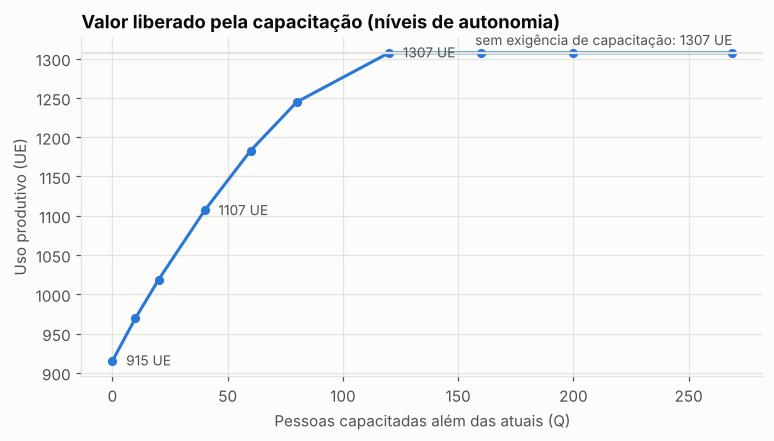

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trein.capacitacoes, trein.valor, color=AZUL, lw=2, marker='o', ms=5)
ax.axhline(base['valor'], color=GRADE, lw=1.5)
ax.text(trein.capacitacoes.max(), base['valor'] + 10, f"sem exigência de capacitação: {base['valor']:.0f} UE", ha='right', color=TINTA2, fontsize=9)
for _, r in trein[trein.capacitacoes.isin([0, 40, 120])].iterrows():
    ax.annotate(f"{r.valor:.0f} UE", (r.capacitacoes, r.valor), textcoords='offset points', xytext=(9, -3), color=TINTA2, fontsize=9)
ax.set_xlabel('Pessoas capacitadas além das atuais (Q)'); ax.set_ylabel('Uso produtivo (UE)')
ax.set_title('Valor liberado pela capacitação (níveis de autonomia)')
fig.savefig(SAIDA / 'fig4_capacitacao.png'); plt.show()

## 10. Aplicação às 18 empresas

O mesmo modelo, sem nenhum ajuste, é aplicado a cada empresa da base. A empresa sem ferramenta por assento aprovada com preço conhecido fica de fora.

In [18]:
linhas = []
for emp in empresas.company_id:
    Pe = parametros(emp)
    if not Pe['pares']:
        linhas.append(dict(empresa=emp, nome=empresas.set_index('company_id').company_name[emp], obs='sem ferramenta por assento aprovada'))
        continue
    Ae = avaliar_atual(Pe); Re = resolver(Pe); Rcc = resolver(Pe, orcamento='cc')
    Rmin = resolver(Pe, meta_valor=Ae['valor'])          # custo mínimo para entregar o valor de hoje
    linhas.append(dict(empresa=emp, nome=empresas.set_index('company_id').company_name[emp], ativos=len(Pe['dep_de']),
                       orcamento=round(Pe['B'].sum()), custo_atual=round(Ae['custo']), valor_atual=round(Ae['valor'], 1),
                       ociosas=Ae['ociosas'], fora_politica=Ae['fora_politica'], status_base=Re['status'],
                       custo_otimo=round(Re['custo']), valor_otimo=round(Re['valor'], 1),
                       custo_min_valor_atual=round(Rmin['custo']), cc_com_cobertura=Rcc['status']))
emp_tab = pd.DataFrame(linhas)
emp_tab['ganho_valor'] = (emp_tab.valor_otimo / emp_tab.valor_atual - 1)
emp_tab['variacao_custo_mesmo_valor'] = emp_tab.custo_min_valor_atual / emp_tab.custo_atual - 1
emp_tab.to_csv(SAIDA / 'empresas.csv', index=False)
fmt = lambda g: f'{g:+.0%}' if pd.notna(g) else ''
display(emp_tab.assign(ganho_valor=emp_tab.ganho_valor.map(fmt),
                       variacao_custo_mesmo_valor=emp_tab.variacao_custo_mesmo_valor.map(fmt))
        [['empresa', 'nome', 'ativos', 'orcamento', 'custo_atual', 'valor_atual', 'ociosas', 'fora_politica',
          'valor_otimo', 'ganho_valor', 'custo_min_valor_atual', 'variacao_custo_mesmo_valor', 'cc_com_cobertura', 'obs']])
tot = emp_tab.dropna(subset=['valor_otimo'])
print(f"Total das {len(tot)} empresas: valor {tot.valor_atual.sum():.0f} -> {tot.valor_otimo.sum():.0f} UE "
      f"({tot.valor_otimo.sum()/tot.valor_atual.sum()-1:+.0%}) | ou mesmo valor por {brl(tot.custo_min_valor_atual.sum())} "
      f"em vez de {brl(tot.custo_atual.sum())} ({1-tot.custo_min_valor_atual.sum()/tot.custo_atual.sum():.0%} de economia)")
print(f"Licenças ativas ociosas: {tot.ociosas.sum():.0f}; de ferramentas fora da política: {tot.fora_politica.sum():.0f}; "
      f"empresas em que o orçamento por CC não cobre todo mundo: {(tot.cc_com_cobertura != 'Optimal').sum()}")

,empresa,nome,ativos,orcamento,custo_atual,valor_atual,ociosas,fora_politica,valor_otimo,ganho_valor,custo_min_valor_atual,variacao_custo_mesmo_valor,cc_com_cobertura,obs
0,C01,NexoCode Solucoes,336.0,94369.0,84626.0,522.2,96.0,36.0,1307.5,+150%,48096.0,-43%,Infeasible,NaN
1,C02,Vortice Software,114.0,40707.0,20779.0,131.7,23.0,95.0,292.4,+122%,9700.0,-53%,Optimal,NaN
2,C03,Piloto Digital Sistemas,32.0,19706.0,10415.0,84.5,14.0,30.0,107.2,+27%,5237.0,-50%,Optimal,NaN
3,C04,Cronos Tech Labs,99.0,36667.0,17393.0,176.4,42.0,26.0,350.5,+99%,8006.0,-54%,Optimal,NaN
4,C05,ByteFlow Engenharia de Software,28.0,19156.0,7394.0,36.0,27.0,9.0,55.2,+53%,2134.0,-71%,Optimal,NaN
5,C06,Banco Alterosa S.A.,316.0,92622.0,45847.0,184.5,145.0,226.0,248.1,+34%,60873.0,+33%,Infeasible,NaN
6,C07,Capital Sul Investimentos,67.0,32338.0,14362.0,63.2,88.0,0.0,63.4,+0%,4948.0,-66%,Optimal,NaN
7,C08,Fincredi Solucoes Financeiras,38.0,13219.0,10050.0,37.5,37.0,0.0,46.5,+24%,6824.0,-32%,Infeasible,NaN
8,C09,Metalurgica Vale Forte,306.0,92805.0,65414.0,95.6,454.0,0.0,97.2,+2%,20935.0,-68%,Optimal,NaN
9,C10,Quimica Bandeirantes,127.0,25332.0,16748.0,65.3,189.0,0.0,65.8,+1%,8523.0,-49%,Infeasible,NaN


Total das 17 empresas: valor 1967 -> 3690 UE (+88%) | ou mesmo valor por R$ 252.714 em vez de R$ 386.171 (35% de economia)
Licenças ativas ociosas: 1513; de ferramentas fora da política: 642; empresas em que o orçamento por CC não cobre todo mundo: 7


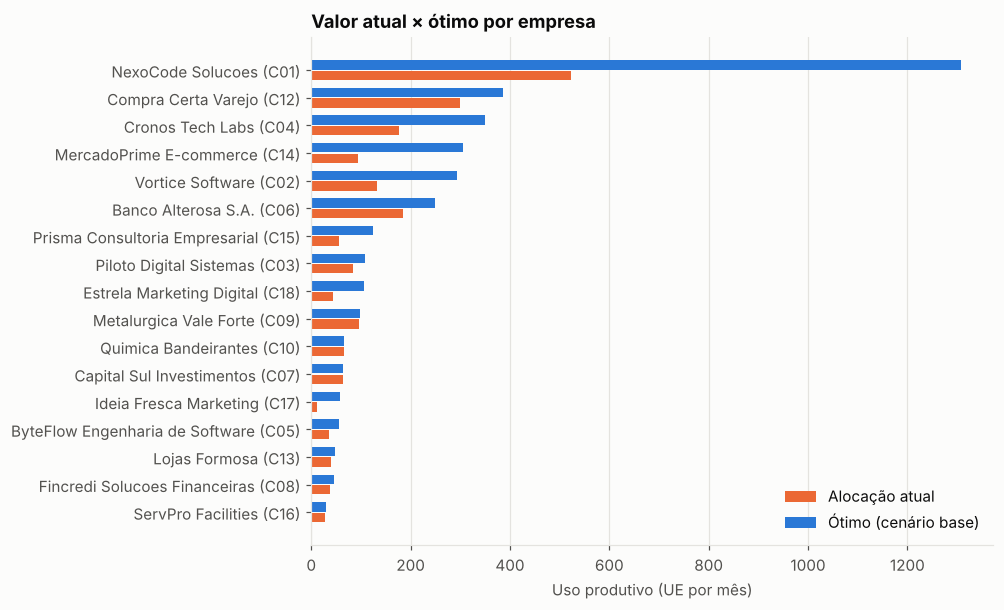

In [19]:
et = emp_tab.dropna(subset=['valor_otimo']).sort_values('valor_otimo')
fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(et)); h = 0.38
ax.barh(yy - h/2, et.valor_atual, h - 0.04, color=LARANJA, label='Alocação atual')
ax.barh(yy + h/2, et.valor_otimo, h - 0.04, color=AZUL, label='Ótimo (cenário base)')
ax.set_yticks(yy, [f'{n} ({c})' for n, c in zip(et.nome, et.empresa)]); ax.grid(axis='y', visible=False)
ax.set_xlabel('Uso produtivo (UE por mês)'); ax.set_title('Valor atual × ótimo por empresa')
ax.legend(loc='lower right')
fig.savefig(SAIDA / 'fig5_empresas.png'); plt.show()

## 11. Conclusões

Os números exatos estão nas tabelas acima e em `resultados/`. O relatório (`README.md`) resume e interpreta.

**Limitações.**

- $v_{e,t}$ mede uso, não resultado de negócio: requisições bem-sucedidas são um indicador indireto de produtividade.
- Quem nunca usou uma ferramenta recebe $v=0$, então o modelo não aposta em adoção nova.
- A base é sintética. O orçamento por centro de custo e o gasto real foram gerados de forma independente, e é isso que produz o descompasso da seção 3.
- O câmbio de R$ 5,50 é uma premissa. Seu efeito é pequeno, porque o consumo em US$ é menos de 2% do orçamento.